<a href="https://colab.research.google.com/github/Manjunathtelugu/Full-stack/blob/main/House_price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  
(20640, 9)
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64


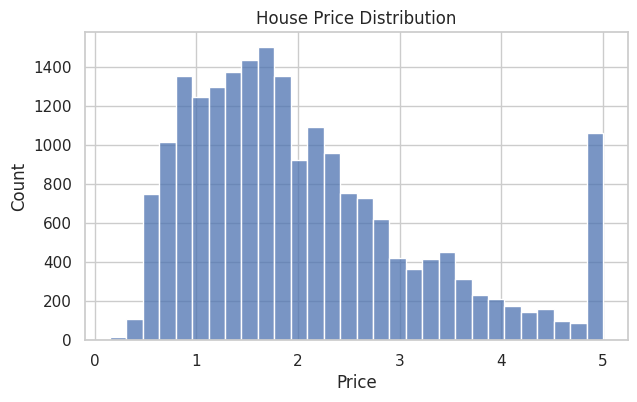

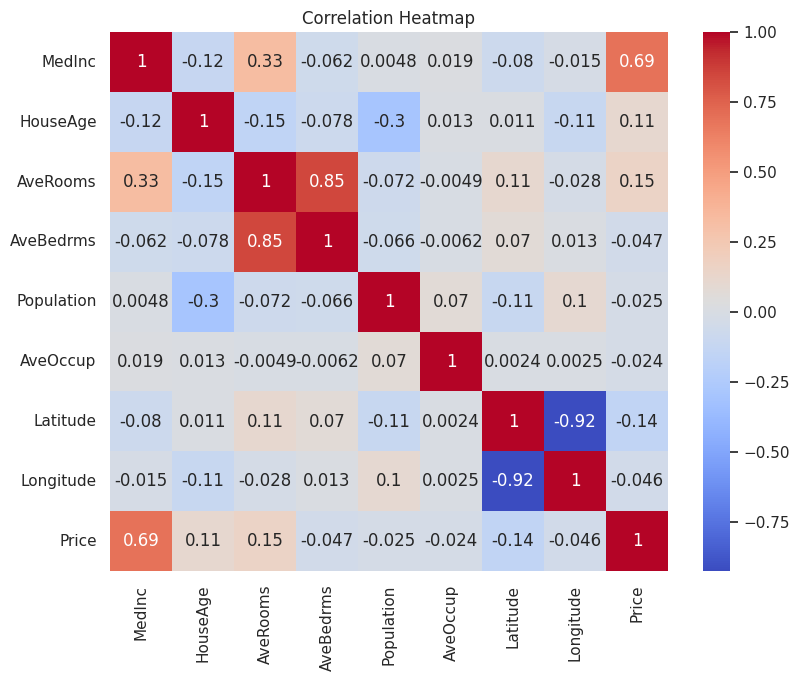

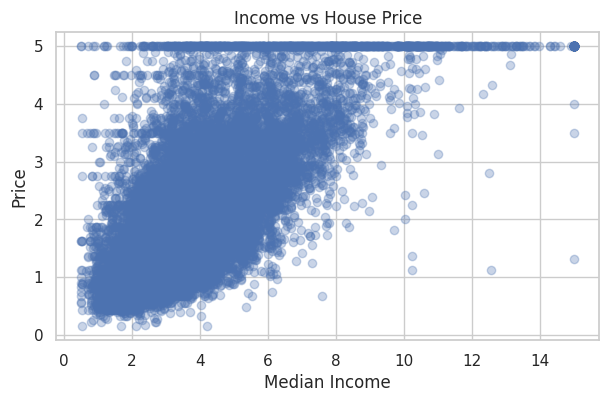

Linear Regression R2 : 0.576
Linear Regression RMSE: 0.746
Random Forest R2     : 0.805
Random Forest RMSE   : 0.505


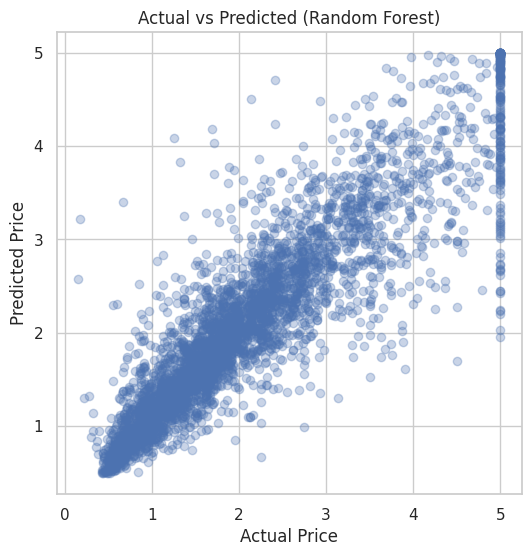

In [ ]:
# ----- Step 1: Import libraries -----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# ----- Step 2: Load the data -----
data = fetch_california_housing(as_frame=True)
df = data.frame
df = df.rename(columns={"MedHouseVal": "Price"})   # Price is in $100,000s

print(df.head())          # first 5 rows
print(df.shape)           # rows and columns
print(df.isnull().sum())  # check missing values

# ----- Step 3: Clean the data -----
df = df.dropna()              # remove rows with missing values
df = df.drop_duplicates()     # remove duplicate rows

# ----- Step 4: Graph 1 - Price distribution -----
plt.figure(figsize=(7, 4))
sns.histplot(df["Price"], bins=30)
plt.title("House Price Distribution")
plt.show()

# ----- Step 5: Graph 2 - Correlation heatmap -----
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# ----- Step 6: Graph 3 - Income vs Price -----
plt.figure(figsize=(7, 4))
plt.scatter(df["MedInc"], df["Price"], alpha=0.3)
plt.xlabel("Median Income")
plt.ylabel("Price")
plt.title("Income vs House Price")
plt.show()

# ----- Step 7: Split data into train and test -----
X = df.drop("Price", axis=1)   # input features
y = df["Price"]                # what we want to predict
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ----- Step 8: Train the models -----
lr = LinearRegression()
lr.fit(X_train, y_train)

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# ----- Step 9: Check the results -----
lr_pred = lr.predict(X_test)
rf_pred = rf.predict(X_test)

print("Linear Regression R2 :", round(r2_score(y_test, lr_pred), 3))
print("Linear Regression RMSE:", round(np.sqrt(mean_squared_error(y_test, lr_pred)), 3))
print("Random Forest R2     :", round(r2_score(y_test, rf_pred), 3))
print("Random Forest RMSE   :", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 3))

# ----- Step 10: Graph 4 - Actual vs Predicted -----
plt.figure(figsize=(6, 6))
plt.scatter(y_test, rf_pred, alpha=0.3)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()
